1. Calling Libraries and Reading Datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, root_mean_squared_error, classification_report 

In [ ]:

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

file_path = "Online Retail.xlsx"
try:
    df = pd.read_excel("Online Retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})
except FileNotFoundError:
    df = pd.read_csv(
        "OnlineRetail.csv",
        encoding="ISO-8859-1",
        dtype={"InvoiceNo": str, "StockCode": str},
    )

print(f"Initial Dataset Shape: {df.shape}")

Initial Dataset Shape: (541909, 8)


2. Data Type Conversion and Missing Value Imputation

In [4]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce").astype(float)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

df["Quantity"] = df["Quantity"].fillna(df["Quantity"].mean()).round().astype(int)
df["UnitPrice"] = df["UnitPrice"].fillna(df["UnitPrice"].mean())

df.dropna(subset=["InvoiceNo", "InvoiceDate"], inplace=True)
df["InvoiceNo"] = df["InvoiceNo"].str.strip()

C:\Users\Dell\AppData\Local\Temp\ipykernel_7112\2713926234.py:8: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["InvoiceNo", "InvoiceDate"], inplace=True)


3. Guest Checkout Verification (Grouping Missing CustomerIDs by InvoiceNo)

In [5]:
invoice_customer_map = df.groupby("InvoiceNo")["CustomerID"].transform("first")
df["CustomerID"] = df["CustomerID"].fillna(invoice_customer_map)

guest_invoices = df[df["CustomerID"].isna()]["InvoiceNo"].nunique()
print(f"Verified 'Guest Checkout' Invoices: {guest_invoices}")

df["Is_Guest"] = df["CustomerID"].isna()
df["CustomerID"] = df["CustomerID"].fillna(-1).astype(int)

Verified 'Guest Checkout' Invoices: 3710


4. Handling Returns (C) and Pricing Errors to Calculate Net Revenue

In [7]:
df_valid_price = df[df["UnitPrice"] > 0].copy()

is_return = df_valid_price["InvoiceNo"].str.startswith("C", na=False)
returns_df = df_valid_price[is_return].copy()
sales_df = df_valid_price[~is_return].copy()

sales_df = sales_df[sales_df["Quantity"] > 0].copy()

sales_df["GrossLineRevenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]
returns_df["ReturnLineAmount"] = returns_df["Quantity"].abs() * returns_df["UnitPrice"]

returned_by_cust_item = (
    returns_df.groupby(["CustomerID", "StockCode"])
    .agg(ReturnedQty=("Quantity", lambda x: x.abs().sum()), ReturnedValue=("ReturnLineAmount", "sum"))
    .reset_index()
)

cust_item_totals = sales_df.groupby(["CustomerID", "StockCode"])[
    "GrossLineRevenue"
].transform("sum")

sales_df = sales_df.merge(
    returned_by_cust_item, on=["CustomerID", "StockCode"], how="left"
)
sales_df["ReturnedValue"] = sales_df["ReturnedValue"].fillna(0.0)
sales_df["ReturnedQty"] = sales_df["ReturnedQty"].fillna(0)

sales_df["AllocatedReturn"] = (
    (sales_df["GrossLineRevenue"] / cust_item_totals.replace(0, np.nan))
    * sales_df["ReturnedValue"]
).fillna(0.0)

sales_df["TotalLineRevenue"] = (
    sales_df["GrossLineRevenue"] - sales_df["AllocatedReturn"]
).clip(lower=0.0)

5. Feature Engineering (UK vs. International Market & Time Features)

In [8]:
sales_df["Is_UK"] = np.where(sales_df["Country"] == "United Kingdom", 1, 0)
sales_df["Market"] = np.where(sales_df["Is_UK"] == 1, "UK", "International")
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour
sales_df["Quarter"] = sales_df["InvoiceDate"].dt.to_period("Q")

6. Return Rate Analysis & UK vs. International Performance

In [9]:
total_gross_rev = sales_df["GrossLineRevenue"].sum()
total_return_val = returns_df["ReturnLineAmount"].sum()
total_net_rev = sales_df["TotalLineRevenue"].sum()
overall_return_rate = (total_return_val / total_gross_rev) * 100

print(f"Total Gross Revenue:   £{total_gross_rev:,.2f}")
print(f"Total Return Value:    £{total_return_val:,.2f} ({overall_return_rate:.2f}% Return Rate)")
print(f"Total Net Revenue:     £{total_net_rev:,.2f}")

market_summary = sales_df.groupby("Market").agg(
    Orders=("InvoiceNo", "nunique"),
    Net_Revenue=("TotalLineRevenue", "sum"),
    Units_Sold=("Quantity", "sum"),
)
market_summary["Revenue_Share_%"] = (market_summary["Net_Revenue"] / total_net_rev) * 100
print(market_summary)

Total Gross Revenue:   £10,666,684.54
Total Return Value:    £896,812.49 (8.41% Return Rate)
Total Net Revenue:     £9,566,167.15
               Orders   Net_Revenue  Units_Sold  Revenue_Share_%
Market                                                          
International    1941  1.499691e+06      925986        15.677032
UK              18019  8.066476e+06     4662390        84.322968


7. Best-Selling Products Analysis

In [10]:
product_perf = (
    sales_df.groupby(["StockCode", "Description"])
    .agg(
        Total_Units=("Quantity", "sum"),
        Net_Revenue=("TotalLineRevenue", "sum"),
        Order_Frequency=("InvoiceNo", "nunique"),
    )
    .reset_index()
)

top_10_rev = product_perf.sort_values(by="Net_Revenue", ascending=False).head(10)
print(top_10_rev[["StockCode", "Description", "Net_Revenue", "Total_Units"]].to_string(index=False))

StockCode                        Description   Net_Revenue  Total_Units
      DOT                     DOTCOM POSTAGE 163817.166482          706
    22423           REGENCY CAKESTAND 3 TIER 129704.582023        13879
   85123A WHITE HANGING HEART T-LIGHT HOLDER  83077.181006        37599
   85099B            JUMBO BAG RED RETROSPOT  78237.989809        48474
    47566                      PARTY BUNTING  74128.410881        18295
    23084                 RABBIT NIGHT LIGHT  65879.276247        30788
    22086    PAPER CHAIN KIT 50'S CHRISTMAS   60973.223529        19355
     POST                            POSTAGE  59348.744572         3150
    84879      ASSORTED COLOUR BIRD ORNAMENT  57265.475963        36461
    79321                      CHILLI LIGHTS  51167.276032        10306


8. Bulk (Wholesale) vs. Individual (Retail) Purchasing Behavior

In [11]:
order_summary = (
    sales_df.groupby(["InvoiceNo", "Is_Guest", "Market"])
    .agg(
        Order_Revenue=("TotalLineRevenue", "sum"),
        Total_Items=("Quantity", "sum"),
        Unique_SKUs=("StockCode", "nunique"),
    )
    .reset_index()
)

order_summary["Buyer_Segment"] = np.where(
    (order_summary["Total_Items"] >= 50) | (order_summary["Order_Revenue"] >= 500),
    "Bulk / Wholesale",
    "Individual / Retail",
)

segment_analysis = order_summary.groupby("Buyer_Segment").agg(
    Order_Count=("InvoiceNo", "count"),
    Total_Revenue=("Order_Revenue", "sum"),
    AOV=("Order_Revenue", "mean"),
    Avg_Units_Per_Order=("Total_Items", "mean"),
)
segment_analysis["Revenue_Share_%"] = (
    segment_analysis["Total_Revenue"] / segment_analysis["Total_Revenue"].sum()
) * 100
print(segment_analysis)

                     Order_Count  Total_Revenue         AOV  \
Buyer_Segment                                                 
Bulk / Wholesale           16309   9.296571e+06  570.027063   
Individual / Retail         3651   2.695958e+05   73.841627   

                     Avg_Units_Per_Order  Revenue_Share_%  
Buyer_Segment                                              
Bulk / Wholesale              337.856950        97.181778  
Individual / Retail            21.437141         2.818222  


9. Trend Analysis: Monthly Revenue, Hourly Activity, and Average Order Value (AOV)

In [12]:
monthly_trends = (
    sales_df.groupby("YearMonth")
    .agg(Net_Revenue=("TotalLineRevenue", "sum"), Total_Orders=("InvoiceNo", "nunique"))
    .reset_index()
)
monthly_trends["AOV"] = monthly_trends["Net_Revenue"] / monthly_trends["Total_Orders"]
monthly_trends["YearMonth_Str"] = monthly_trends["YearMonth"].astype(str)

overall_aov = order_summary["Order_Revenue"].mean()
print(f"Overall Average Order Value (AOV): £{overall_aov:,.2f}")
print(monthly_trends[["YearMonth_Str", "Net_Revenue", "Total_Orders", "AOV"]].to_string(index=False))

hourly_activity = (
    sales_df.groupby("Hour")
    .agg(Orders=("InvoiceNo", "nunique"), Net_Revenue=("TotalLineRevenue", "sum"))
    .reset_index()
)

Overall Average Order Value (AOV): £479.27
YearMonth_Str  Net_Revenue  Total_Orders        AOV
      2010-12 7.488743e+05          1559 480.355535
      2011-01 5.577019e+05          1086 513.537682
      2011-02 4.922509e+05          1100 447.500845
      2011-03 6.552219e+05          1454 450.634052
      2011-04 4.810139e+05          1246 386.046491
      2011-05 7.077372e+05          1681 421.021557
      2011-06 6.708656e+05          1533 437.616204
      2011-07 6.652670e+05          1475 451.028471
      2011-08 6.835577e+05          1361 502.246654
      2011-09 1.004244e+06          1837 546.676116
      2011-10 1.047801e+06          2040 513.627893
      2011-11 1.410256e+06          2769 509.301467
      2011-12 4.413759e+05           819 538.920538


10. Pareto Principle (80/20 Rule) Verification

In [13]:
pareto_df = (
    sales_df.groupby("StockCode")["TotalLineRevenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
pareto_df["Cumulative_Revenue"] = pareto_df["TotalLineRevenue"].cumsum()
pareto_df["Cumulative_Rev_%"] = (pareto_df["Cumulative_Revenue"] / total_net_rev) * 100
pareto_df["Product_Rank_%"] = ((pareto_df.index + 1) / len(pareto_df)) * 100

top_20_cutoff = pareto_df[pareto_df["Product_Rank_%"] <= 20.0]
rev_from_top_20 = top_20_cutoff["Cumulative_Rev_%"].max()

products_for_80_rev = pareto_df[pareto_df["Cumulative_Rev_%"] <= 80.0]["Product_Rank_%"].max()

print(f"Top 20% of products generate: {rev_from_top_20:.2f}% of total net revenue.")
print(f"80% of total net revenue is generated by: {products_for_80_rev:.2f}% of products.")

Top 20% of products generate: 77.83% of total net revenue.
80% of total net revenue is generated by: 21.88% of products.


11. Dead Stock Identification (No Sales in Last 90 Days)

In [14]:
max_date = sales_df["InvoiceDate"].max()
cutoff_90_days = max_date - pd.Timedelta(days=90)

last_sale_per_product = (
    sales_df.groupby(["StockCode", "Description"])
    .agg(
        Last_Sale_Date=("InvoiceDate", "max"),
        Historical_Units_Sold=("Quantity", "sum"),
        Historical_Revenue=("TotalLineRevenue", "sum"),
    )
    .reset_index()
)

dead_stock = last_sale_per_product[
    last_sale_per_product["Last_Sale_Date"] < cutoff_90_days
].sort_values(by="Last_Sale_Date")

print(f"Total Active SKUs: {len(last_sale_per_product)}")
print(f"Dead Stock SKUs (0 sales since {cutoff_90_days.date()}): {len(dead_stock)}")
print(dead_stock.head(10).to_string(index=False))

Total Active SKUs: 4161
Dead Stock SKUs (0 sales since 2011-09-10): 829
StockCode                         Description      Last_Sale_Date  Historical_Units_Sold  Historical_Revenue
    84854                 GIRLY PINK TOOL SET 2010-12-01 09:41:00                      5           24.750000
    82615 PINK MARSHMALLOW SCARF KNITTING KIT 2010-12-01 16:11:00                     36           91.800000
    22778                GLASS BELL JAR SMALL 2010-12-02 10:53:00                      4           13.132906
    22777                GLASS BELL JAR LARGE 2010-12-02 10:53:00                      2           17.000000
    22776        CAKESTAND, 3 TIER, LOVEHEART 2010-12-02 10:53:00                      2           19.900000
   35271S                GOLD PRINT PAPER BAG 2010-12-02 13:49:00                     19            3.610000
    85144     JARDIN ETCHED GLASS BUTTER DISH 2010-12-02 15:46:00                      1            7.250000
    21268            VINTAGE BLUE TINSEL REEL 2010-12-02

12. Executive Strategic EDA Visualization Dashboard

C:\Users\Dell\AppData\Local\Temp\ipykernel_7112\1000718449.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


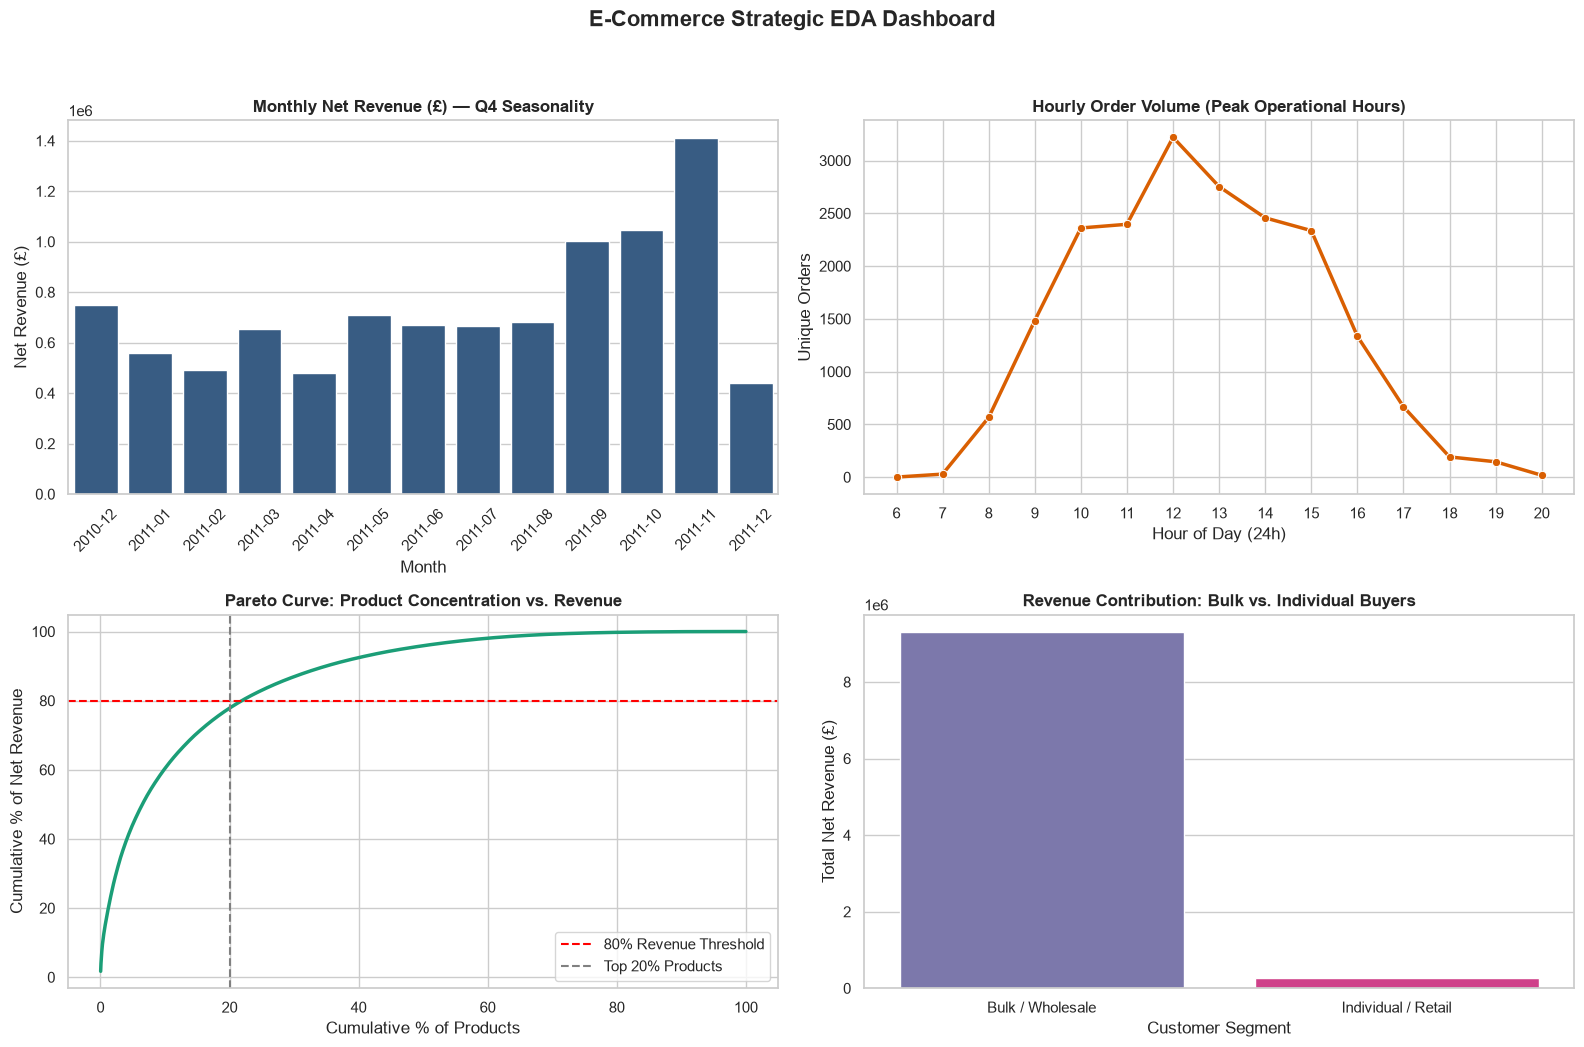

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("E-Commerce Strategic EDA Dashboard", fontsize=16, fontweight="bold")

sns.barplot(data=monthly_trends, x="YearMonth_Str", y="Net_Revenue", ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Monthly Net Revenue (£) — Q4 Seasonality", fontweight="bold")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Net Revenue (£)")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=hourly_activity, x="Hour", y="Orders", marker="o", ax=axes[0, 1], color="#d95f02", linewidth=2.5
)
axes[0, 1].set_title("Hourly Order Volume (Peak Operational Hours)", fontweight="bold")
axes[0, 1].set_xlabel("Hour of Day (24h)")
axes[0, 1].set_ylabel("Unique Orders")
axes[0, 1].set_xticks(range(hourly_activity["Hour"].min(), hourly_activity["Hour"].max() + 1))

axes[1, 0].plot(pareto_df["Product_Rank_%"], pareto_df["Cumulative_Rev_%"], color="#1b9e77", linewidth=2.5)
axes[1, 0].axhline(80, color="red", linestyle="--", label="80% Revenue Threshold")
axes[1, 0].axvline(20, color="gray", linestyle="--", label="Top 20% Products")
axes[1, 0].set_title("Pareto Curve: Product Concentration vs. Revenue", fontweight="bold")
axes[1, 0].set_xlabel("Cumulative % of Products")
axes[1, 0].set_ylabel("Cumulative % of Net Revenue")
axes[1, 0].legend()

sns.barplot(
    data=segment_analysis.reset_index(),
    x="Buyer_Segment",
    y="Total_Revenue",
    ax=axes[1, 1],
    palette=["#7570b3", "#e7298a"],
)
axes[1, 1].set_title("Revenue Contribution: Bulk vs. Individual Buyers", fontweight="bold")
axes[1, 1].set_xlabel("Customer Segment")
axes[1, 1].set_ylabel("Total Net Revenue (£)")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.dayofweek
sales_df["Month"] = sales_df["InvoiceDate"].dt.month

features = ["Quantity", "UnitPrice", "Is_UK", "Is_Guest", "Hour", "DayOfWeek", "Month"]
target = "TotalLineRevenue"

X = sales_df[features].copy()
X["Is_Guest"] = X["Is_Guest"].astype(int)
y = sales_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (424083, 7)
X_test shape:  (106021, 7)
y_train shape: (424083,)
y_test shape:  (106021,)


C:\Users\Dell\AppData\Local\Temp\ipykernel_7112\3292341143.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.dayofweek


In [21]:
import joblib


joblib.dump(sales_df, "code.pkl")

['code.pkl']